In [3]:
import pickle

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.stats import pearsonr

from utils.notebook_utils import *

pd.set_option("display.float_format", "{:.2f}".format)

In [4]:
data_small = pickle.load(open("data/multi_path_summary_cov_small_shuffle.pkl", "rb"))
data_big = pickle.load(open("data/multi_path_summary_cov_big_shuffle.pkl", "rb"))

data_small.keys()

dict_keys(['alert_genes', 'alert_names', 'scored_path_df', 'p_val', 'v_total_paths', 'v_hits', 'v_paths', 'v_pathways', 'v_pathway_names', 'h_total_paths', 'h_hits', 'h_pathways'])

In [5]:
def jaccard(a, b):
    sa, sb = set(a), set(b)
    union = sa | sb
    if not union:
        return 0.0
    return len(sa & sb) / len(union)

def overlap_coefficient(a, b):
    sa, sb = set(a), set(b)
    overlap = sa & sb
    return len(overlap) / min(len(sa), len(sb))

#### Overlap alert genes

In [6]:
overlap = set(data_small["alert_genes"]) & set(data_big["alert_genes"])
union = set(data_small["alert_genes"]) | set(data_big["alert_genes"])
jac_index = jaccard(data_small["alert_genes"], data_big["alert_genes"])
overlap_coef = len(overlap) / min(len(data_small["alert_genes"]), len(data_big["alert_genes"]))

print(f"Jaccard Index: {jac_index:.2f}")
print(f"Overlap coefficient: {overlap_coef:.2f}")

Jaccard Index: 0.16
Overlap coefficient: 0.33


In [7]:
for i, ag in enumerate(data_small["alert_genes"]):
    if ag in overlap:
        print(data_small["alert_names"][i])

B2M
SAT1
IFITM1
RPS27
IFITM3
TMSB4X
FTL
HLA-A


In [8]:
len(data_small["alert_genes"]), len(data_big["alert_genes"])

(34, 24)

#### Most important genes

In [9]:
len(data_small["scored_path_df"])

247

In [13]:
data_small["scored_path_df"]

,Gene,n_paths,pct_included,avg_score,z_score
node_id,,,,,
43740568,S (v),1386,33.37,0.62,8.58
2033,EP300,1343,32.33,0.63,0.38
43740575,N (v),1323,31.85,0.62,5.77
1387,CREBBP,861,20.73,0.62,0.17
43740570,E (v),624,15.02,0.62,3.84
...,...,...,...,...,...
3399,ID3,1,0.02,0.57,-0.05
5934,RBL2,1,0.02,0.56,-0.07
64750,SMURF2,1,0.02,0.55,-0.06


In [12]:
merged = data_big["scored_path_df"].merge(data_small["scored_path_df"], on='alert', suffixes=('_1', '_2'))

r, p = pearsonr(merged['z_score_1'], merged['z_score_2'])
print(f"Pearson r = {r:.3f}, p = {p:.3g}, n = {len(merged)}")

KeyError: 'alert'

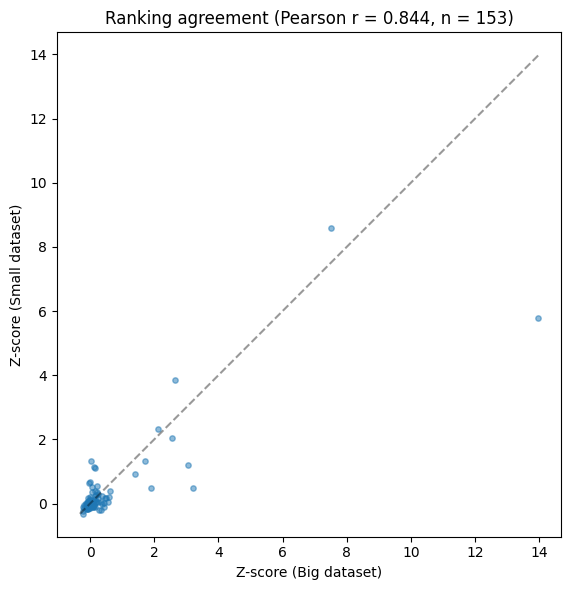

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(merged['z_score_1'], merged['z_score_2'], alpha=0.5, s=15)

# 1:1 reference line
lims = [
    min(merged['z_score_1'].min(), merged['z_score_2'].min()),
    max(merged['z_score_1'].max(), merged['z_score_2'].max())
]
ax.plot(lims, lims, 'k--', alpha=0.4, label='y = x')

ax.set_xlabel('Z-score (Big dataset)')
ax.set_ylabel('Z-score (Small dataset)')
ax.set_title(f'Ranking agreement (Pearson r = {r:.3f}, n = {len(merged)})')
#ax.legend()
ax.set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.show()

#### Found pathways

In [ ]:
sm_pathways = {pw.split("(")[0][:-1]: pw.split("(")[1][:-1] for pw in data_small["v_pathways"]}
bg_pathways = {pw.split("(")[0][:-1]: pw.split("(")[1][:-1] for pw in data_big["v_pathways"]}

print("Shared:")
for pw in (set(sm_pathways) & set(bg_pathways)):
    print(pw)
print("---")
print("SM only pathways:")
for pw in set(sm_pathways) - set(set(sm_pathways) & set(bg_pathways)):
    print(pw)
print("---")
print("BG only pathways:")
for pw in set(bg_pathways) - set(set(sm_pathways) & set(bg_pathways)):
    print(pw)
print("---")


Shared:
SMAD2/SMAD3:SMAD4 heterotrimer regulates transcription
Interferon alpha/beta signaling
SARS-CoV-2 activates/modulates innate and adaptive immune responses
Interferon gamma signaling
---
SM only pathways:
PKR-mediated signaling
ISG15 antiviral mechanism
---
BG only pathways:
Regulation of TP53 Activity through Phosphorylation
Ub-specific processing proteases
The role of GTSE1 in G2/M progression after G2 checkpoint
Regulation of TP53 Activity through Methylation
Constitutive Signaling by NOTCH1 PEST Domain Mutants
Constitutive Signaling by NOTCH1 HD+PEST Domain Mutants
Signaling by ALK fusions and activated point mutants
Recruitment and ATM-mediated phosphorylation of repair and signaling proteins at DNA double strand breaks
Autodegradation of the E3 ubiquitin ligase COP1
Oxidative Stress Induced Senescence
Regulation of TP53 Degradation
Stabilization of p53
---


#### paths of pathways

In [ ]:
data_big["v_pathway_names"]

{'R-HSA-6804757': 'Regulation of TP53 Degradation',
 'R-HSA-6804760': 'Regulation of TP53 Activity through Methylation',
 'R-HSA-9725370': 'Signaling by ALK fusions and activated point mutants',
 'R-HSA-349425': 'Autodegradation of the E3 ubiquitin ligase COP1',
 'R-HSA-877300': 'Interferon gamma signaling',
 'R-HSA-5689880': 'Ub-specific processing proteases',
 'R-HSA-909733': 'Interferon alpha/beta signaling',
 'R-HSA-9705671': 'SARS-CoV-2 activates/modulates innate and adaptive immune responses',
 'R-HSA-6804756': 'Regulation of TP53 Activity through Phosphorylation',
 'R-HSA-8852276': 'The role of GTSE1 in G2/M progression after G2 checkpoint',
 'R-HSA-2173796': 'SMAD2/SMAD3:SMAD4 heterotrimer regulates transcription',
 'R-HSA-5693565': 'Recruitment and ATM-mediated phosphorylation of repair and signaling proteins at DNA double strand breaks',
 'R-HSA-2559580': 'Oxidative Stress Induced Senescence',
 'R-HSA-2894862': 'Constitutive Signaling by NOTCH1 HD+PEST Domain Mutants',
 'R-HS

In [ ]:
for k in data_big["v_paths"][7314].keys():
    print(data_big["v_pathway_names"][k])

Constitutive Signaling by NOTCH1 PEST Domain Mutants
Constitutive Signaling by NOTCH1 HD+PEST Domain Mutants
SMAD2/SMAD3:SMAD4 heterotrimer regulates transcription
Ub-specific processing proteases
Autodegradation of the E3 ubiquitin ligase COP1
Recruitment and ATM-mediated phosphorylation of repair and signaling proteins at DNA double strand breaks
Regulation of TP53 Activity through Phosphorylation
Regulation of TP53 Degradation
Regulation of TP53 Activity through Methylation
Stabilization of p53
The role of GTSE1 in G2/M progression after G2 checkpoint
Oxidative Stress Induced Senescence
Signaling by ALK fusions and activated point mutants


In [ ]:
for s in data_small["v_paths"]:
    for l in data_big["v_paths"]:
        if s == l:
            print(s)
            print(data_small["v_paths"][s])
            print(data_big["v_paths"][s])
            print()

567
{'R-HSA-877300': frozenset({3665, 10379, np.int64(6772), 567}), 'R-HSA-9705671': frozenset({3665, np.int64(1387), 6773, 567})}
{'R-HSA-877300': [(np.int64(6772), 10379, 3665, 567), (np.int64(6772), 3665, 567)], 'R-HSA-9705671': [(np.int64(6772), 3665, 567), (np.int64(6773), 3665, 567), (np.int64(6772), 6773, 3665, 567), (np.int64(6773), 6772, 3665, 567)]}

8519
{'R-HSA-909733': frozenset({np.int64(6772), 6773, 1958, 8519})}
{'R-HSA-909733': [(np.int64(5610), 6772, 1958, 8519), (np.int64(6773), 1958, 8519), (np.int64(6772), 6773, 1958, 8519), (np.int64(6773), 6772, 1958, 8519), (np.int64(6772), 1958, 8519)]}

10410
{'R-HSA-909733': frozenset({3665, 10410, 10379, np.int64(6773)})}
{'R-HSA-909733': [(np.int64(6772), 6773, 3665, 10410), (np.int64(6773), 10379, 3665, 10410), (np.int64(6773), 3665, 10410), (np.int64(5610), 6772, 3665, 10410), (np.int64(6773), 6772, 3665, 10410), (np.int64(6772), 3665, 10410), (np.int64(6772), 10379, 3665, 10410)]}

3105
{'R-HSA-909733': frozenset({3105, 

### Unpruned graphs

In [ ]:
graph_cov_small = pickle.load(open("data/covid_small_shuf_scored_0.45001683867176984.pkl", "rb"))
graph_cov_large = pickle.load(open("data/covid_big_shuf_scored_0.37208189148051174.pkl", "rb"))
graph_hsv = pickle.load(open("data/hsv_scored_0.7201545590002386.pkl", "rb"))
graph_cov_rand = pickle.load(open("data/covid_rand_scored_0.578443057622332.pkl", "rb"))

cs_cutoff = 0.45001683867176984
cl_cutoff = 0.37208189148051174
h_cutoff = 0.7201545590002386
cr_cutoff = 0.5821237683187181

In [ ]:
gcs_edges = set(graph_cov_small.edges())
gcl_edges = set(graph_cov_large.edges())
gh_edges = set(graph_hsv.edges())

gcc_edges = gcs_edges & gcl_edges # graph covid combined edges
gvc_edges = gcc_edges & gh_edges # graph virus combined edges
print(jaccard(gcs_edges, gcl_edges), len(gcs_edges), len(gcl_edges), len(gcc_edges), len(gvc_edges))

0.5431395793856005 97531 67784 58186 32105


In [ ]:
covid_edge_scores = []
for edge in gcc_edges:
    if edge[0] == edge[1]:
        continue
    gcl_score = graph_cov_large.edges[edge[0], edge[1]]["real_weight"]
    gcs_score = graph_cov_small.edges[edge[0], edge[1]]["real_weight"]
    if gcl_score == 1.0 and gcs_score == 1.0:
        continue

    if abs(gcl_score) > cl_cutoff and abs(gcs_score) > cs_cutoff:
        covid_edge_scores.append((gcl_score, gcs_score))

combined_edge_score = []
for edge in gvc_edges:
    if edge[0] == edge[1]:
        continue
    gh_score = graph_hsv.edges[edge[0], edge[1]]["real_weight"]
    gcl_score = graph_cov_large.edges[edge[0], edge[1]]["real_weight"]
    gcs_score = graph_cov_small.edges[edge[0], edge[1]]["real_weight"]
    gcr_score = graph_cov_rand.edges[edge[0], edge[1]]["real_weight"]

    combined_edge_score.append((gcl_score, gcs_score, gh_score))

In [ ]:
df = pd.DataFrame(combined_edge_score, columns=["gcl", "gcs", "gh"])
corr_matrix = df.corr(method="pearson")
print(corr_matrix)

     gcl  gcs   gh
gcl 1.00 0.25 0.10
gcs 0.25 1.00 0.02
gh  0.10 0.02 1.00


### Graph path score

In [ ]:
pathway = "R-HSA-5689880"
alert_node = 7314

path = list(data_big["v_paths"][alert_node][pathway][-1])

In [ ]:
path

[np.int64(4088), 4087, 7157, 7314]

In [ ]:
path = order_path_by_distance_from_end(list(data_big["v_paths"][alert_node][pathway][-1]), graph_cov_large, alert_node)
path

[np.int64(6772), np.int64(6773), np.int64(3659), 3105]

<Axes: title={'center': 'Edge weights along path: Ub-specific processing proteases'}, xlabel='Edge', ylabel='Edge weight'>

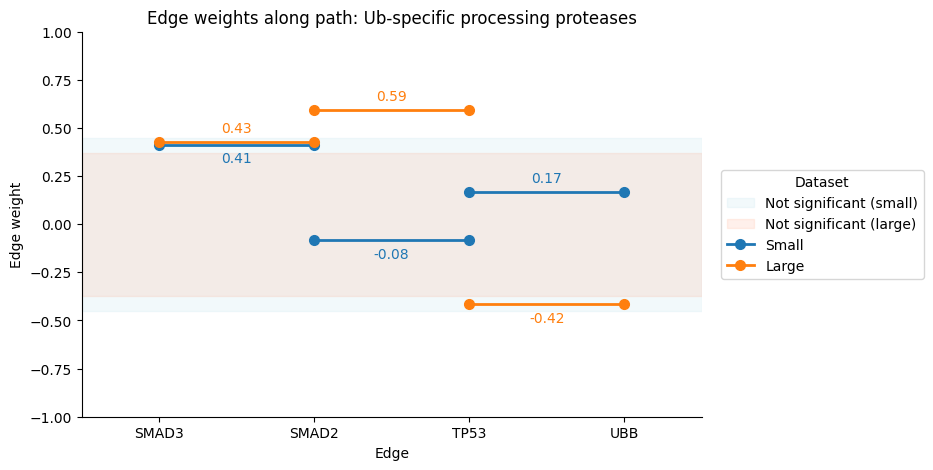

In [ ]:
plot_path_weights(graph_cov_small, graph_cov_large, path, pathway=data_big["v_pathway_names"][pathway], band_value=(cs_cutoff, cl_cutoff))